# Viviendas iniciadas al año, libres y protegidas

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "viviendas-iniciadas"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Viviendas iniciadas al año, libres y protegidas"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Viviendas"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuántas viviendas empiezan a construirse cada año en España, en total y separadas en libres (de promoción privada, a precio de mercado) y protegidas (con precio o renta limitados por la normativa, de promoción pública o privada), según la estadística del Ministerio de Vivienda y Agenda Urbana que difunde el Banco de España.

**Cómo se lee.** Es un recuento anual: indica cuánta vivienda nueva se pone en marcha, no cuánta se termina (una vivienda tarda en general más de un año en acabarse). El total es la suma de las libres y las protegidas.

**Limitaciones.**
- La serie de viviendas libres empieza más tarde que la de protegidas; antes, el total publicado solo recoge las protegidas, así que el total y las libres de esos años se dejan sin dato (ver notas).
- Las protegidas incluyen las de promoción privada: no son solo vivienda pública. La serie de las de promoción pública está en el notebook `vivienda-protegida-iniciada`.
- Es un total nacional: no distingue dónde se construye.
- Solo España: no hay una serie internacional de viviendas iniciadas en las fuentes autorizadas (Eurostat publica permisos de construcción, que son otro concepto, y solo para países europeos).

## 2. Descarga

Series mensuales del Boletín Estadístico del Banco de España: `D_1KB02000` (viviendas iniciadas, total), `D_1KB02100` (libres) y `D_1KB02200` (protegidas). El fetcher suma los doce meses de cada año completo.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import bde


def descargar():
    """Devuelve (DataFrame con las series `espana` (total), `libres` y `protegidas`, lista de FuenteMeta)."""
    return bde.get(
        {"D_1KB02000": "espana", "D_1KB02100": "libres", "D_1KB02200": "protegidas"},
        agregacion="suma",
        desde=DESDE,
    )


publicado, fuentes_descarga = descargar()

## 3. Transformación

El total publicado antes de que empiece la serie de viviendas libres solo contiene vivienda protegida, así que esos años se dejan sin dato en lugar de mostrar un total que no lo es. Las libres y las protegidas van como desglose del total (`desglose`); se comprueba que suman el total publicado.

In [ ]:
ancho = publicado.pivot(index="periodo", columns="serie", values="valor")
INICIO_LIBRES = int(ancho["libres"].first_valid_index())
ancho.loc[ancho.index < INICIO_LIBRES, "espana"] = float("nan")

# Comprobación: libres + protegidas = total publicado (en los años con las tres series)
completos = ancho.dropna()
diferencia = (completos["libres"] + completos["protegidas"] - completos["espana"]).abs().max()
assert diferencia < 1, f"libres + protegidas no suman el total (diferencia máxima {diferencia})"

DESGLOSE = {"libres": "Libres", "protegidas": "Protegidas"}
df = ancho[["espana", *DESGLOSE]].reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]
fuentes = fuentes_descarga

NOTAS = [
    "Ministerio de Vivienda y Agenda Urbana, difundido por el Banco de España: viviendas iniciadas, libres y protegidas.",
    f"Antes de {INICIO_LIBRES} el total publicado solo recoge las viviendas protegidas (la serie de viviendas libres empieza ese año), por lo que el total de esos años queda sin dato.",
    "Protegidas: viviendas con precio de venta o renta limitados por la normativa de vivienda protegida, de promoción pública o privada. Libres: el resto.",
    "Serie mensual: se suma cada año natural; el año en curso, incompleto, no se incluye.",
    "Solo España: no hay una serie internacional de viviendas iniciadas en las fuentes autorizadas; Eurostat publica permisos de construcción, que son otro concepto, y solo para países europeos.",
]

## 4. Visualización

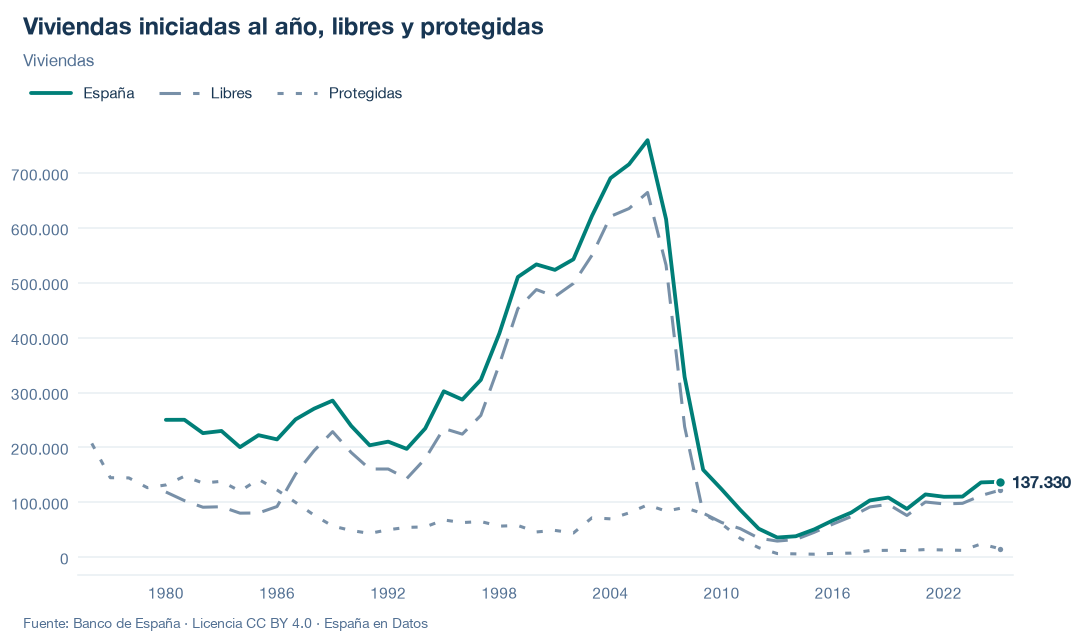

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, desglose=DESGLOSE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    desglose=DESGLOSE, path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/viviendas-iniciadas.json y data/viviendas-iniciadas.csv


## 6. Fuentes, notas y licencia

- Banco de España, Boletín Estadístico, series `D_1KB02000` (total), `D_1KB02100` (libres) y `D_1KB02200` (protegidas), con datos del Ministerio de Vivienda y Agenda Urbana.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.